In [20]:
# Versão para Atividade 4
import geopandas as gpd
import numpy as np
import random
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

from shapely.geometry import Polygon

import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as ctx

import numpy as np
from matplotlib import pyplot as plt
from itertools import product
import pandas as pd

# Importa e reprojeta os arquivos
AREAS_INTERESSE = gpd.read_file('PEmSE/area_interesse.shp').to_crs('EPSG:3857')
PASSAGENS_SAR = gpd.read_file('PEmSE/passagens_SAR.shp').to_crs('EPSG:3857')

# Calcula a área em km2 segundo a projeção definida
AREAS_INTERESSE['area_km2'] = AREAS_INTERESSE.to_crs('EPSG:3857').geometry.area / 1000000
PASSAGENS_SAR['area_km2'] = PASSAGENS_SAR.to_crs('EPSG:3857').geometry.area / 1000000

WEIGHTS = [1, 1.5, 0.5] # AC, NP e SO

VERBOSE_OUTPUT = True
VERBOSE_EVALUATION = True

print(f"Number of passages: {len(PASSAGENS_SAR)}")

print(AREAS_INTERESSE)

print(AREAS_INTERESSE.sum(numeric_only=True))

Number of passages: 702
   DN  area                                           geometry       area_km2
0   1     3  POLYGON ((-6064650.101 -312930.486, -6052850.3...    3738.925071
1   1     4  POLYGON ((-5351101.095 -365993.039, -5336852.3...   28187.026492
2   1     7  POLYGON ((-5973591.897 -677640.649, -5964909.0...    7564.353656
3   1     8  POLYGON ((-6581833.982 -675625.641, -6572483.2...   39069.397812
4   1    11  POLYGON ((-6355412.972 -1060595.143, -6352296....    7764.852837
5   1    12  POLYGON ((-7080761.696 -770407.192, -7076976.8...  122662.452378
6   1    13  POLYGON ((-6066876.463 -1293839.277, -6064650....    7037.422047
DN               7.000000
area            58.000000
area_km2    216024.430292
dtype: float64


In [21]:
# indexes = np.array(PASSAGENS_SAR.index.tolist())
# # gerar máscara binária
# rng = np.random.default_rng()
# mascara_int = rng.integers(0, 2, size = len(PASSAGENS_SAR), dtype = int)
# mascara_int

def evaluate_passagens(mask_bin):
    selected_passagens = PASSAGENS_SAR.iloc[mask_bin.astype(bool)]
    # Retorna zero se nenhuma passagem foi selecionada
    if selected_passagens.empty:
        return 0

    # Calcula a interseção das passagens com a área de interesse
    intersecao = gpd.overlay(
        AREAS_INTERESSE,
        selected_passagens,
        how='intersection'
    )

    # Calcula a soma das áreas de interseção
    area_intersections = intersecao.geometry.area.sum() / 1000000

    # Calcula a área total coberta, sem contar as sobreposições
    uniao = intersecao.geometry.union_all()
    area_uniao = uniao.area / 1000000

    # Calcula as métricas da solução
    overlap = (area_intersections - area_uniao) / (area_intersections + area_uniao)
    area_covered = area_uniao / AREAS_INTERESSE['area_km2'].sum()
    passages = len(selected_passagens) / len(PASSAGENS_SAR)

    # Define os pesos da função objetivo
    w1, w2, w3 = WEIGHTS

    # Calcula o score da solução
    score = w1 * area_covered - w2 * passages - w3 * overlap

    if VERBOSE_EVALUATION:
        print(
            f"Área coberta (AC): {area_covered:.6f} |",
            f"Número de passagens (NP): {len(selected_passagens)} |",
            f"Sobreposição (SO): {overlap:.6f} |",
            f"Score (Loss): {score:.6f}"
        )

    return score

def extrair_metricas_tabela(best_mask):
    # 1. Filtra as passagens selecionadas pelo indivíduo
    selected_passagens = PASSAGENS_SAR.iloc[best_mask.astype(bool)].copy()
    
    if selected_passagens.empty:
        return {"area_nao_coberta_pct": 100.0, "passagens_com_sobreposicao": 0}

    # 2. Interseção com as Áreas de Interesse
    intersecao = gpd.overlay(AREAS_INTERESSE, selected_passagens, how='intersection')
    
    # 3. Cálculo da Área Não Coberta (%)
    uniao = intersecao.geometry.union_all()
    area_uniao_km2 = uniao.area / 1e6
    area_total_km2 = AREAS_INTERESSE['area_km2'].sum()
    
    area_covered = area_uniao_km2 / area_total_km2
    area_nao_coberta_pct = (1.0 - area_covered) * 100.0

    # 4. Cálculo de "Passagens com sobreposição"
    # Faz um auto-join espacial entre as passagens selecionadas para detectar interseções
    sjoin_overlaps = gpd.sjoin(
        selected_passagens, 
        selected_passagens, 
        how='inner', 
        predicate='intersects'
    )
    
    # Descarta a auto-interseção (linha com ela mesma)
    sjoin_overlaps = sjoin_overlaps[sjoin_overlaps.index != sjoin_overlaps.index_right]
    
    # Contagem de passagens únicas que se sobrepõem a pelo menos uma outra
    passagens_com_sobreposicao = sjoin_overlaps.index.nunique()
    
    print(f"Passagens com sobreposição: {passagens_com_sobreposicao}")
    print(f"Área não coberta: {area_nao_coberta_pct:.2f}%")
    
    return {
        "passagens_com_sobreposicao": passagens_com_sobreposicao,
        "area_nao_coberta_pct": area_nao_coberta_pct
    }

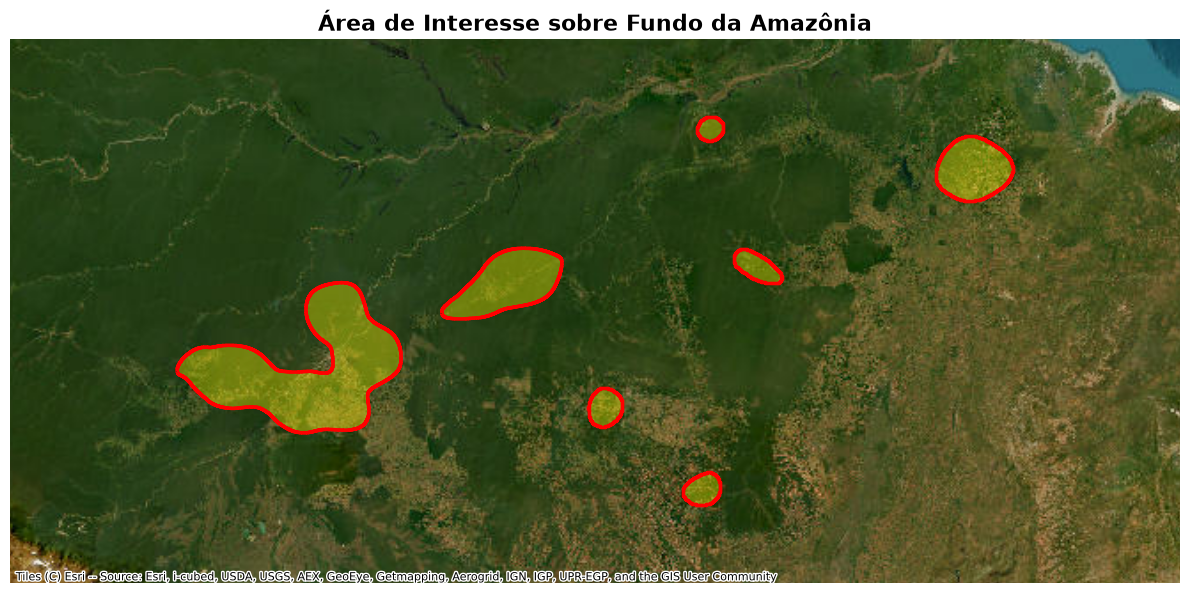

In [22]:
# Reprojetar para o sistema usado pelo mapa-base
area_plot = AREAS_INTERESSE.to_crs(epsg=3857)

# Criar figura
fig, ax = plt.subplots(figsize=(12, 10))

# Limites da área de interesse
xmin, ymin, xmax, ymax = area_plot.total_bounds

# Adiciona uma margem ao redor da área
dx = xmax - xmin
dy = ymax - ymin

margem_x = dx * 0.20
margem_y = dy * 0.20

ax.set_xlim(xmin - margem_x, xmax + margem_x)
ax.set_ylim(ymin - margem_y, ymax + margem_y)

# Adiciona o fundo de satélite
ctx.add_basemap(
    ax,
    source=ctx.providers.Esri.WorldImagery,
    crs=area_plot.crs
)

# Plotar a área de interesse preenchida
area_plot.plot(
    ax=ax,
    facecolor='yellow',
    edgecolor='red',
    alpha=0.35,
    linewidth=2.5,
    zorder=2
)

# Opcional: desenhar também só o contorno por cima
area_plot.boundary.plot(
    ax=ax,
    color='red',
    linewidth=2.5,
    zorder=3
)

ax.set_title('Área de Interesse sobre Fundo da Amazônia', fontsize=16, fontweight='bold')
ax.set_axis_off()

plt.tight_layout()
plt.savefig('area_interesse_amazonia_fundo.png', dpi=300, bbox_inches='tight')
plt.show()

In [23]:
def fitness_default(fob_value):
    """
    Função de aptidão para minimização.
    Garante que valores menores de fob tenham maior fitness na roleta.
    """
    if fob_value >= 0:
        return 1.0 / (1.0 + fob_value)
    return 1.0 + abs(fob_value)

class Individual:
    def __init__(self, x_bin, fob, fitness_func):
        self._fob = fob
        self._fitness = fitness_func
        self.x_bin = np.asarray(x_bin, dtype=int)

        # A própria fob avalia diretamente a máscara binária
        self.fob = float(fob(self.x_bin))
        self.fitness = float(fitness_func(self.fob))


class Population:
    def __init__(self, pop_size, crom_size, fob, fitness_func, p_init=0.5):
        self.pop_size = pop_size
        self.individuals = []
        rng = np.random.default_rng()
        for _ in range(pop_size):
            # Vetor binário de tamanho N correspondente às geometrias
            x_bin = (rng.random(size=crom_size) < p_init).astype(int)
            # x_bin = (rng.random(size=crom_size)).astype(int)
            self.individuals.append(Individual(x_bin, fob, fitness_func))


class Roulette:
    def __init__(self, population):
        self.roulette_range = []
        total_fit = sum(ind.fitness for ind in population.individuals)

        # Prevenção contra divisão por zero
        if total_fit == 0:
            total_fit = 1e-9

        cumulative = 0.0
        for individual in population.individuals:
            cumulative += individual.fitness / total_fit
            self.roulette_range.append(cumulative)
        self.roulette_range[-1] = 1.0

    def spin(self):
        r = np.random.uniform(0, 1)
        for i, v in enumerate(self.roulette_range):
            if v > r:
                return i
        return len(self.roulette_range) - 1

def tournament_selection(individuals, method="min", k=3):
    candidates = np.random.choice(individuals, size=k, replace=False)
    comparator = min if method == "min" else max
    return comparator(candidates, key=lambda ind: ind.fob)

def ranking_selection(individuals, method="min"):
    n = len(individuals)
    # Ordena do pior (rank 1) para o melhor (rank N)
    # Se min: maiores fobs são os piores; se max: menores fobs são os piores
    reverse_order = True if method == "min" else False
    sorted_inds = sorted(individuals, key=lambda ind: ind.fob, reverse=reverse_order)

    # Probabilidades lineares: rank i tem peso i
    ranks = np.arange(1, n + 1)
    probs = ranks / ranks.sum()

    idx = np.random.choice(n, p=probs)
    return sorted_inds[idx]

def mutation(individual, pm):
    rng = np.random.default_rng()
    x_bin_mut = []
    for bit in individual.x_bin:
        prob = rng.random()
        if prob > pm:
            x_bin_mut.append(bit)
        else:
            x_bin_mut.append(bit ^ 1)
    return Individual(x_bin_mut, individual._fob, individual._fitness)

def cross(parent_1, parent_2):
    pc = int(len(parent_1.x_bin) / 2)
    child_1_bits = np.concatenate([parent_1.x_bin[:pc], parent_2.x_bin[pc:]])
    child_2_bits = np.concatenate([parent_2.x_bin[:pc], parent_1.x_bin[pc:]])

    child_1 = Individual(child_1_bits, parent_1._fob, parent_1._fitness)
    child_2 = Individual(child_2_bits, parent_1._fob, parent_1._fitness)
    return child_1, child_2

class GeoGeneticAlgorithm:
    def __init__(self):
        self.population = None
        self.best = None
        self.best_mask = None
        self.best_f_history = []
        self.fob = None
        self.method = "min"
        self.selection_method = "roulette"

    def _select_parent(self, roulette, selection_method, tournament_size):
        """Helper interno para retornar um indivíduo de acordo com o operador escolhido."""
        if selection_method == "roulette":
            idx = roulette.spin()
            return self.population.individuals[idx]
        elif selection_method == "tournament":
            return tournament_selection(
                self.population.individuals,
                method=self.method,
                k=tournament_size,
            )
        elif selection_method == "ranking":
            return ranking_selection(
                self.population.individuals,
                method=self.method,
            )

    def run(
        self,
        fob,
        n_geometries,
        pop_size=100,
        n_generations=50,
        pm=0.01,
        p_init=0.5,
        fitness_func=None,
        elitism=True,
        seed=None,
        method="min",                  # 'min' ou 'max'
        selection_method="tournament", # 'roulette', 'tournament' ou 'ranking'
        tournament_size=3,             # Tamanho 'k' do torneio (se selection_method='tournament')
    ):
        if method not in ("min", "max"):
            raise ValueError("O parâmetro 'method' deve ser 'min' ou 'max'.")

        valid_selections = ("roulette", "tournament", "ranking")
        if selection_method not in valid_selections:
            raise ValueError(f"O parâmetro 'selection_method' deve ser um de: {valid_selections}")

        self.method = method
        self.selection_method = selection_method
        best_selector = min if method == "min" else max

        # Fitness padrão caso use Roleta e nenhuma função customizada seja passada
        if fitness_func is None:
            if method == "min":
                fitness_func = lambda score: 1.0 / (1.0 + max(score, 0))
            else:
                fitness_func = lambda score: max(score, 0.0)

        if seed is not None:
            np.random.seed(seed)

        self.fob = fob
        self.best_f_history = []

        self.population = Population(
            pop_size, n_geometries, fob, fitness_func, p_init=p_init
        )

        for generation in range(n_generations):
            current_best = best_selector(
                self.population.individuals, key=lambda ind: ind.fob
            )
            self.best_f_history.append(current_best.fob)

            # Instancia a roleta apenas se ela for o método escolhido
            roulette = Roulette(self.population) if selection_method == "roulette" else None
            new_individuals = []

            # Elitismo: preserva a melhor solução atual
            if elitism:
                new_individuals.append(current_best)

            while len(new_individuals) < pop_size:
                # Seleção flexível dos progenitores
                parent_1 = self._select_parent(roulette, selection_method, tournament_size)
                parent_2 = self._select_parent(roulette, selection_method, tournament_size)

                child_1, child_2 = cross(parent_1, parent_2)

                child_1 = mutation(child_1, pm)
                child_2 = mutation(child_2, pm)

                new_individuals.append(child_1)
                if len(new_individuals) < pop_size:
                    new_individuals.append(child_2)

            if VERBOSE_OUTPUT:
                best = best_selector(new_individuals, key=lambda ind: ind.fob)
                best_mask = best.x_bin.astype(bool)
                best_score = best.fob

                print(
                    "================>",
                    f"Geração {generation + 1}: ",
                    f"Melhor score ({self.method} | {self.selection_method}): {best_score:.4f} |",
                    f"Geometrias selecionadas: {best_mask.sum()}",
                )

            self.population.individuals = new_individuals

        # Melhor indivíduo final
        self.best = best_selector(
            self.population.individuals, key=lambda ind: ind.fob
        )
        self.best_mask = self.best.x_bin.astype(bool)

        return self.best_mask, self.best.fob

    def plot_convergence(self):
        """Plota a curva de convergência do score."""
        if not self.best_f_history:
            raise ValueError("Execute o método 'run' antes de gerar o gráfico.")

        fig, ax = plt.subplots(figsize=(9, 4))

        geracoes = range(1, len(self.best_f_history) + 1)
        ax.plot(
            geracoes,
            self.best_f_history,
            marker="o",
            markersize=3,
            color="tab:blue",
        )

        ax.xaxis.set_major_locator(MaxNLocator(integer=True))

        ax.set_xlabel("Geração")
        ax.set_ylabel("Melhor Score f(x)")
        ax.set_title(
            f"Convergência do AG ({self.method.upper()} | Seleção: {self.selection_method.capitalize()})"
        )
        ax.grid(True, linestyle="--", alpha=0.6)

        plt.tight_layout()
        plt.show()

================> Geração 1:  Melhor score (max | tournament): 0.2657 | Geometrias selecionadas: 19
================> Geração 2:  Melhor score (max | tournament): 0.3610 | Geometrias selecionadas: 28
================> Geração 3:  Melhor score (max | tournament): 0.4568 | Geometrias selecionadas: 46
================> Geração 4:  Melhor score (max | tournament): 0.5275 | Geometrias selecionadas: 55
================> Geração 5:  Melhor score (max | tournament): 0.5371 | Geometrias selecionadas: 59
================> Geração 6:  Melhor score (max | tournament): 0.5493 | Geometrias selecionadas: 74
================> Geração 7:  Melhor score (max | tournament): 0.5493 | Geometrias selecionadas: 74
================> Geração 8:  Melhor score (max | tournament): 0.5493 | Geometrias selecionadas: 74
================> Geração 9:  Melhor score (max | tournament): 0.5673 | Geometrias selecionadas: 96
================> Geração 10:  Melhor score (max | tournament): 0.5673 | Geometrias selecionadas: 96

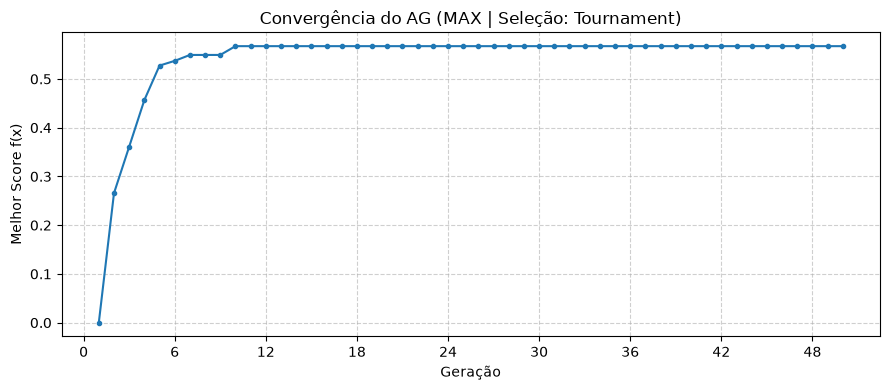

In [25]:
VERBOSE_EVALUATION = False
VERBOSE_OUTPUT = True

WEIGHTS = [1, 1.5, 0.5] # AC, NP e SO
# WEIGHTS = [1, 2, 2] # AC, NP e SO

ga = GeoGeneticAlgorithm()
best_mask, best_score = ga.run(
    fob              = evaluate_passagens,
    n_geometries     = len(PASSAGENS_SAR),
    pop_size         = 30,
    n_generations    = 50,
    pm               = 0.02,
    p_init           = 0,
    elitism          = True,
    seed             = 42,
    method           = "max",
    selection_method = "tournament", # 'roulette', 'tournament' ou 'ranking'
    tournament_size  = 5,            # Tamanho 'k' do torneio (se selection_method='tournament')
)

print(f"\nMelhor score obtido: {best_score:.4f}")
print(f"Geometrias selecionadas: {best_mask.sum()}")

# Filtrando o GeoDataFrame original com a melhor máscara encontrada
gdf_otimizado_max = PASSAGENS_SAR.iloc[best_mask]

# Plot da convergência
ga.plot_convergence()

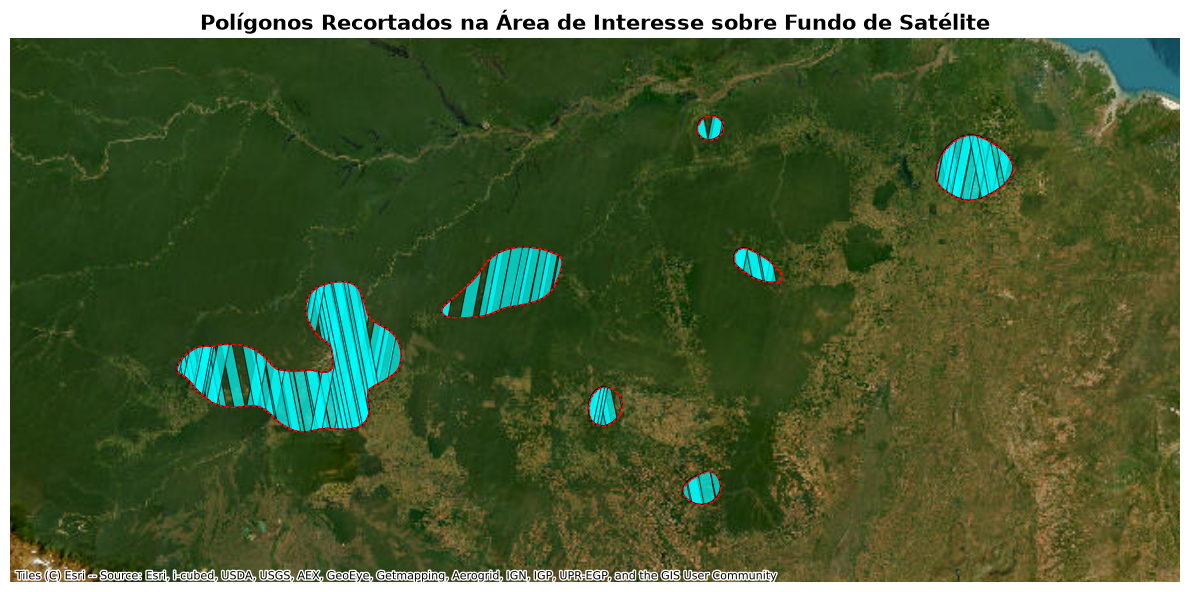

In [26]:
# 2. Recortar o gdf_final usando a geometria da área de interesse
gdf_recortado = gdf_otimizado_max.clip(AREAS_INTERESSE)

# 3. Reprojetar ambos para EPSG:3857 (usado pelo mapa-base do contextily)
area_plot = AREAS_INTERESSE.to_crs(epsg=3857)
gdf_recortado_plot = gdf_recortado.to_crs(epsg=3857)

# Criar figura
fig, ax = plt.subplots(figsize=(12, 10))

# Limites da área de interesse
xmin, ymin, xmax, ymax = area_plot.total_bounds

# Adiciona uma margem ao redor da área
dx = xmax - xmin
dy = ymax - ymin

margem_x = dx * 0.20
margem_y = dy * 0.20

ax.set_xlim(xmin - margem_x, xmax + margem_x)
ax.set_ylim(ymin - margem_y, ymax + margem_y)

# Adiciona o fundo de satélite
ctx.add_basemap(
    ax,
    source=ctx.providers.Esri.WorldImagery,
    crs=area_plot.crs
)

# 4. Plotar o gdf final recortado
gdf_recortado_plot.plot(
    ax=ax,
    color='cyan',         # ou use 'column=nome_coluna' caso tenha classes
    alpha=0.7,
    edgecolor='black',
    linewidth=0.8,
    zorder=2,
    label='Polígonos Selecionados'
)

# 5. Desenhar o contorno da área de interesse por cima
area_plot.boundary.plot(
    ax=ax,
    color='red',
    linewidth=1,
    linestyle='--',
    zorder=3,
    label='Área de Interesse'
)

ax.set_title('Polígonos Recortados na Área de Interesse sobre Fundo de Satélite', fontsize=15, fontweight='bold')
ax.set_axis_off()

plt.tight_layout()
plt.savefig('gdf_recortado_amazonia.png', dpi=300, bbox_inches='tight')
plt.show()

Executando Seleção Gulosa prévia...
Seleção Gulosa concluída: 60 passagens selecionadas | Cobertura: 99.21%

Iteração 00 | Score Inicial: 0.9532 | Passagens ativas: 61
Iteração 05 | Score: 0.9532 | Passagens selecionadas: 61/702
Iteração 10 | Score: 0.9532 | Passagens selecionadas: 61/702


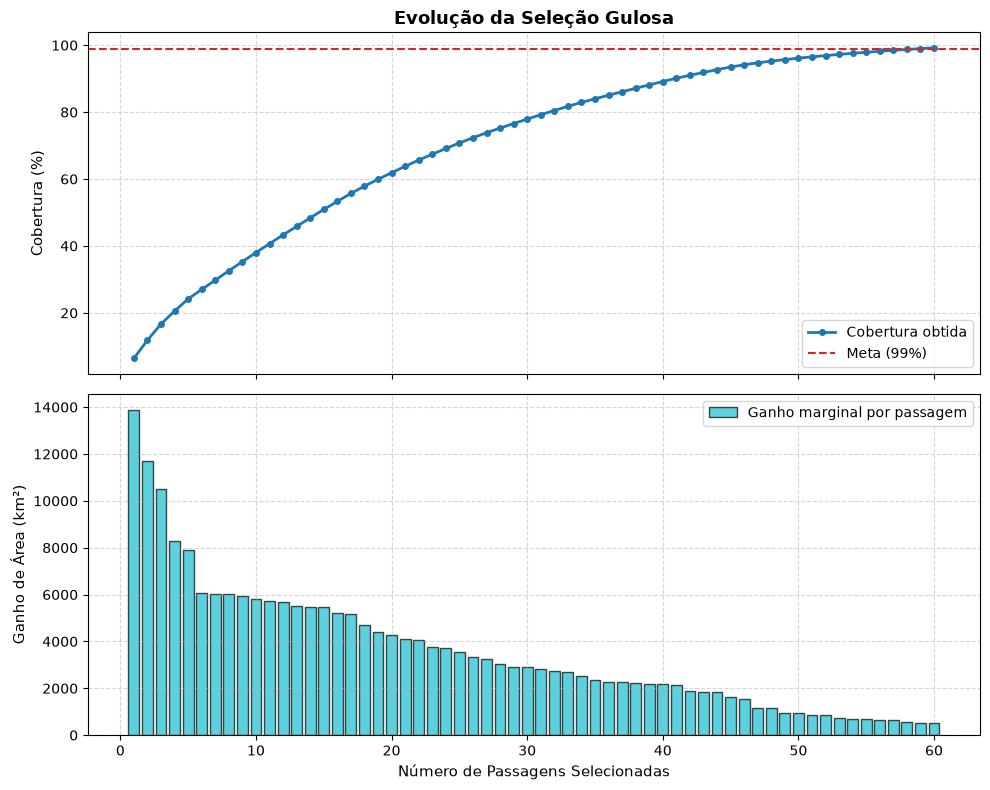


--- RESULTADO DA OTIMIZAÇÃO ---
Score Máximo Encontrado: 0.95316
Total de passagens: 61 de 702
Índices selecionados: [4, 10, 32, 72, 78, 88, 91, 99, 111, 151, 152, 191, 211, 216, 234, 259, 271, 272, 283, 289, 290, 291, 292, 293, 311, 324, 361, 366, 370, 417, 426, 428, 445, 447, 455, 468, 507, 515, 516, 517, 518, 519, 531, 559, 560, 562, 570, 571, 572, 574, 630, 631, 632, 648, 650, 657, 661, 676, 679, 680, 685]


In [40]:
import numpy as np
import geopandas as gpd
from shapely.ops import unary_union

eval_cache = {}


def evaluate_passagens(mask_bin):
    selected_passagens = PASSAGENS_SAR.iloc[
        np.asarray(mask_bin).astype(bool)
    ]
    # Retorna penalidade para solução vazia
    if selected_passagens.empty:
        return -999.0
    # Calcula a interseção das passagens com a área de interesse
    intersecao = gpd.overlay(
        AREAS_INTERESSE,
        selected_passagens,
        how='intersection'
    )
    # Verifica se existem interseções
    if intersecao.empty:
        return -999.0
    # Soma das áreas individuais das interseções
    area_intersections = (
        intersecao.geometry.area.sum() / 1_000_000
    )
    # Calcula a união espacial
    if hasattr(intersecao.geometry, 'union_all'):
        uniao = intersecao.geometry.union_all()
    else:
        uniao = unary_union(
            intersecao.geometry.tolist()
        )
    # Área da união sem duplicidade
    area_uniao = uniao.area / 1_000_000
    # Área total de interesse
    if 'area_km2' in AREAS_INTERESSE.columns:
        total_area_interesse = (
            AREAS_INTERESSE['area_km2'].sum()
        )
    else:
        total_area_interesse = (
            AREAS_INTERESSE.geometry.area.sum()
            / 1_000_000
        )
    if total_area_interesse <= 0:
        return -999.0

    # Sobreposição percentual relativa à área acumulada
    denom = area_intersections + area_uniao
    overlap = (
        (area_intersections - area_uniao) / denom
        if denom > 0 else 0.0
    )
    # Cobertura espacial
    area_covered = (
        area_uniao / total_area_interesse
    )
    area_covered = np.clip(
        area_covered, 0.0, 1.0
    )
    # Proporção de passagens selecionadas
    passages_ratio = (
        len(selected_passagens) / len(PASSAGENS_SAR)
    )
    # Pesos
    w1, w2, w3 = WEIGHTS
    # Função objetivo original
    score = (
        w1 * area_covered
        - w2 * passages_ratio
        - w3 * overlap
    )
    # Monitoramento
    if VERBOSE_EVALUATION:
        print(
            f"Área coberta (AC): {area_covered:.6f} |",
            f"Número de passagens (NP): {len(selected_passagens)} |",
            f"Sobreposição (SO): {overlap:.6f} |",
            f"Score (Loss): {score:.6f}"
        )
    return score



def sigmoid(x):
    x = np.clip(x, -10, 10)
    return 1.0 / (1.0 + np.exp(-x))


import numpy as np
import geopandas as gpd
from shapely.ops import unary_union
import matplotlib.pyplot as plt

def selecao_gulosa(alvo_cobertura=0.99, limite_passagens=70):
    """
    Heurística gulosa: seleciona passo a passo a passagem que
    adiciona o maior ganho marginal de cobertura à área de interesse,
    registrando o histórico de evolução a cada iteração.
    """
    n_dim = len(PASSAGENS_SAR)
    
    # Geometria unificada da área de interesse
    if hasattr(AREAS_INTERESSE.geometry, 'union_all'):
        area_total_geom = AREAS_INTERESSE.geometry.union_all()
    else:
        area_total_geom = unary_union(AREAS_INTERESSE.geometry.tolist())
        
    area_total_km2 = area_total_geom.area / 1_000_000

    # Pré-recorte de cada passagem contra a área de interesse
    geometrias_recortadas = []
    for geom in PASSAGENS_SAR.geometry:
        if geom is None or geom.is_empty:
            geometrias_recortadas.append(None)
        else:
            inter = geom.intersection(area_total_geom)
            geometrias_recortadas.append(None if inter.is_empty else inter)

    indices_restantes = [i for i, g in enumerate(geometrias_recortadas) if g is not None]
    selecionadas = []
    cobertura_atual_geom = None
    area_coberta_atual = 0.0

    # Estrutura para armazenar o histórico de cada etapa
    historico = {
        "etapa": [],
        "indice_passagem": [],
        "cobertura_pct": [],
        "ganho_km2": [],
        "area_acumulada_km2": []
    }

    print("Executando Seleção Gulosa prévia...")
    for etapa in range(1, min(limite_passagens, len(indices_restantes)) + 1):
        melhor_indice = None
        maior_ganho = 0.0

        for idx in indices_restantes:
            geom = geometrias_recortadas[idx]
            if cobertura_atual_geom is None:
                ganho = geom.area
            else:
                ganho = geom.difference(cobertura_atual_geom).area

            if ganho > maior_ganho:
                maior_ganho = ganho
                melhor_indice = idx

        if melhor_indice is None or maior_ganho <= 0:
            break

        selecionadas.append(melhor_indice)
        indices_restantes.remove(melhor_indice)

        geom_escolhida = geometrias_recortadas[melhor_indice]
        if cobertura_atual_geom is None:
            cobertura_atual_geom = geom_escolhida
        else:
            cobertura_atual_geom = cobertura_atual_geom.union(geom_escolhida)

        ganho_km2 = maior_ganho / 1_000_000
        area_coberta_atual += maior_ganho
        area_coberta_km2 = area_coberta_atual / 1_000_000
        cobertura_pct = min((area_coberta_km2 / area_total_km2) * 100, 100.0)

        # Registra a iteração no histórico
        historico["etapa"].append(etapa)
        historico["indice_passagem"].append(melhor_indice)
        historico["cobertura_pct"].append(cobertura_pct)
        historico["ganho_km2"].append(ganho_km2)
        historico["area_acumulada_km2"].append(area_coberta_km2)

        if (cobertura_pct / 100.0) >= alvo_cobertura:
            break

    mascara_gulosa = np.zeros(n_dim, dtype=int)
    mascara_gulosa[selecionadas] = 1
    print(f"Seleção Gulosa concluída: {len(selecionadas)} passagens selecionadas | Cobertura: {cobertura_pct:.2f}%\n")
    
    return mascara_gulosa, historico


def run_bpso_tuned(
    n_particles=20,
    n_iterations=50,
    w_max=0.9,
    w_min=0.5,
    c1=2.0,
    c2=2.0,
    v_max=2.0,
    usar_guloso=True,
    alvo_cobertura_guloso=0.99,
    limite_passagens_guloso=70
):
    n_dim = len(PASSAGENS_SAR)
    positions = np.zeros((n_particles, n_dim), dtype=int)

    # 1. Inicialização com inclusão da Solução Gulosa (Warm Start)
    if usar_guloso:
        mascara_gulosa, historico_guloso = selecao_gulosa(
            alvo_cobertura=alvo_cobertura_guloso,
            limite_passagens=limite_passagens_guloso
        )
        # Partícula 0 recebe exatamente a solução gulosa
        positions[0] = mascara_gulosa.copy()

        # Partículas 1 a 4 recebem pequenas mutações da gulosa (busca local no entorno)
        for i in range(1, min(5, n_particles)):
            mutada = mascara_gulosa.copy()
            # Inverte aleatoriamente entre 1 e 3 posições
            flips = np.random.choice(n_dim, size=np.random.randint(1, 4), replace=False)
            mutada[flips] = 1 - mutada[flips]
            if np.any(mutada):
                positions[i] = mutada
            else:
                positions[i] = mascara_gulosa.copy()

        start_idx = min(5, n_particles)
    else:
        start_idx = 0

    # Demais partículas: inicialização esparsa para exploração do espaço de busca
    for i in range(start_idx, n_particles):
        k = np.random.randint(1, min(10, n_dim + 1))
        idx = np.random.choice(n_dim, size=k, replace=False)
        positions[i, idx] = 1

    velocidades = np.random.uniform(-1.0, 1.0, (n_particles, n_dim))

    # 2. Avaliação inicial da população
    pbest_pos = np.copy(positions)
    pbest_scores = np.array([evaluate_passagens(p) for p in positions])

    best_idx = np.argmax(pbest_scores)
    gbest_pos = np.copy(pbest_pos[best_idx])
    gbest_score = pbest_scores[best_idx]

    print(f"Iteração 00 | Score Inicial: {gbest_score:.4f} | Passagens ativas: {gbest_pos.sum()}")

    # 3. Laço principal do BPSO
    for it in range(1, n_iterations + 1):
        # Decaimento linear da inércia
        w = w_max - ((w_max - w_min) * (it / n_iterations))

        for i in range(n_particles):
            r1 = np.random.rand(n_dim)
            r2 = np.random.rand(n_dim)

            velocidades[i] = (
                w * velocidades[i]
                + c1 * r1 * (pbest_pos[i] - positions[i])
                + c2 * r2 * (gbest_pos - positions[i])
            )
            velocidades[i] = np.clip(velocidades[i], -v_max, v_max)

            prob = sigmoid(velocidades[i])
            positions[i] = (np.random.rand(n_dim) < prob).astype(int)

            # Evita vetor zerado
            if not np.any(positions[i]):
                positions[i, np.random.randint(0, n_dim)] = 1

            score = evaluate_passagens(positions[i])

            if score > pbest_scores[i]:
                pbest_scores[i] = score
                pbest_pos[i] = np.copy(positions[i])

                if score > gbest_score:
                    gbest_score = score
                    gbest_pos = np.copy(positions[i])

        if it % 5 == 0 or it == n_iterations:
            print(f"Iteração {it:02d} | Score: {gbest_score:.4f} | Passagens selecionadas: {gbest_pos.sum()}/{n_dim}")

    return gbest_pos, gbest_score, historico_guloso


# --- EXECUÇÃO ---

# 1. Definição dos pesos da função objetivo (cobertura com peso dominante)
WEIGHTS = (1.0, 0.15, 0.20)  # w1=1.0 (cobertura), w2=0.15 (n_passagens), w3=0.20 (sobreposição)

# 2. Executa a otimização com o método guloso integrado
melhor_mascara, melhor_score, historico_guloso = run_bpso_tuned(
    n_particles=30,
    n_iterations=10,
    usar_guloso=True,
    alvo_cobertura_guloso=0.99,
    limite_passagens_guloso=96
)

# 2. Gera o gráfico de evolução
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# Gráfico 1: Cobertura Acumulada (%)
ax1.plot(
    historico_guloso["etapa"],
    historico_guloso["cobertura_pct"],
    marker='o',
    color='tab:blue',
    linewidth=2,
    markersize=4,
    label='Cobertura obtida'
)
ax1.axhline(
    99.0,
    color='tab:red',
    linestyle='--',
    linewidth=1.5,
    label='Meta (99%)'
)
ax1.set_ylabel("Cobertura (%)", fontsize=11)
ax1.set_title("Evolução da Seleção Gulosa", fontsize=13, fontweight='bold')
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(loc="lower right")

# Gráfico 2: Ganho Marginal de Área (km²) a cada nova passagem
ax2.bar(
    historico_guloso["etapa"],
    historico_guloso["ganho_km2"],
    color='tab:cyan',
    edgecolor='black',
    alpha=0.7,
    label='Ganho marginal por passagem'
)
ax2.set_xlabel("Número de Passagens Selecionadas", fontsize=11)
ax2.set_ylabel("Ganho de Área (km²)", fontsize=11)
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()

# 3. Constrói o GeoDataFrame com a melhor solução
passagens_escolhidas = PASSAGENS_SAR.iloc[melhor_mascara.astype(bool)]

# 4. Exibe métricas consolidadas
print("\n" + "="*40)
print("--- RESULTADO DA OTIMIZAÇÃO ---")
print("="*40)
print(f"Score Máximo Encontrado: {melhor_score:.5f}")
print(f"Total de passagens: {len(passagens_escolhidas)} de {len(PASSAGENS_SAR)}")
if 'id_passagem' in passagens_escolhidas.columns:
    print("IDs selecionados:", passagens_escolhidas['id_passagem'].tolist())
else:
    print("Índices selecionados:", passagens_escolhidas.index.tolist())

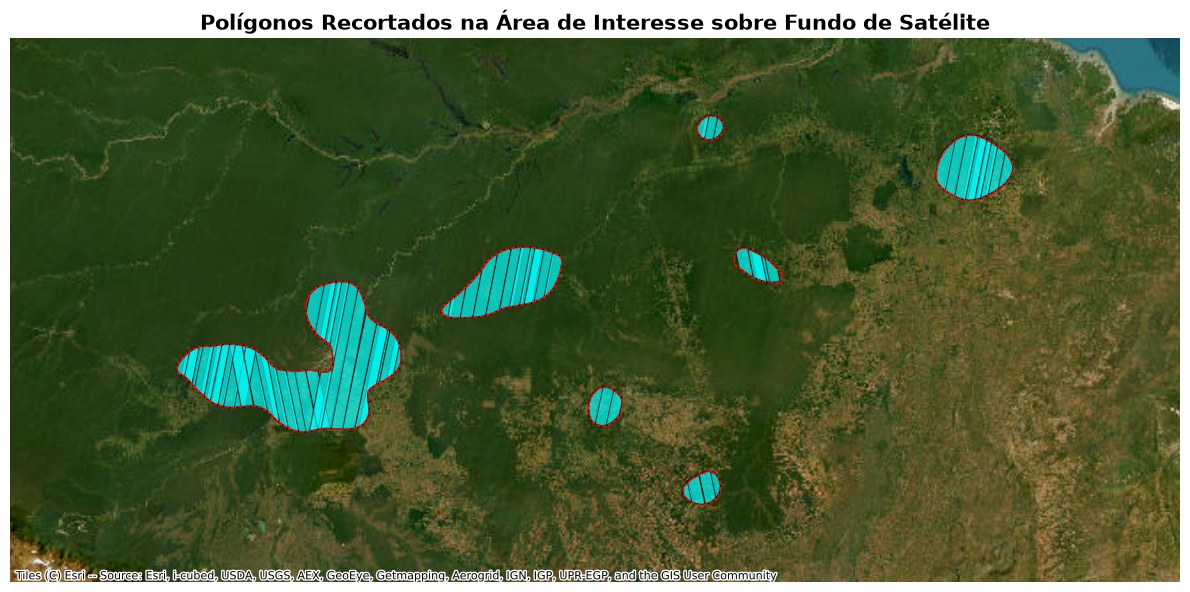

Passagens com sobreposição: 61
Área não coberta: 0.68%


In [41]:
# 2. Recortar o gdf_final usando a geometria da área de interesse
gdf_recortado = passagens_escolhidas.clip(AREAS_INTERESSE)

# 3. Reprojetar ambos para EPSG:3857 (usado pelo mapa-base do contextily)
area_plot = AREAS_INTERESSE.to_crs(epsg=3857)
gdf_recortado_plot = gdf_recortado.to_crs(epsg=3857)

# Criar figura
fig, ax = plt.subplots(figsize=(12, 10))

# Limites da área de interesse
xmin, ymin, xmax, ymax = area_plot.total_bounds

# Adiciona uma margem ao redor da área
dx = xmax - xmin
dy = ymax - ymin

margem_x = dx * 0.20
margem_y = dy * 0.20

ax.set_xlim(xmin - margem_x, xmax + margem_x)
ax.set_ylim(ymin - margem_y, ymax + margem_y)

# Adiciona o fundo de satélite
ctx.add_basemap(
    ax,
    source=ctx.providers.Esri.WorldImagery,
    crs=area_plot.crs
)

# 4. Plotar o gdf final recortado
gdf_recortado_plot.plot(
    ax=ax,
    color='cyan',         # ou use 'column=nome_coluna' caso tenha classes
    alpha=0.7,
    edgecolor='black',
    linewidth=0.8,
    zorder=2,
    label='Polígonos Selecionados'
)

# 5. Desenhar o contorno da área de interesse por cima
area_plot.boundary.plot(
    ax=ax,
    color='red',
    linewidth=1,
    linestyle='--',
    zorder=3,
    label='Área de Interesse'
)

ax.set_title('Polígonos Recortados na Área de Interesse sobre Fundo de Satélite', fontsize=15, fontweight='bold')
ax.set_axis_off()

plt.tight_layout()
plt.savefig('gdf_recortado_amazonia.png', dpi=300, bbox_inches='tight')
plt.show()

# Exemplo de chamada:
metricas = extrair_metricas_tabela(melhor_mascara)

In [ ]:
# Define os valores dos hiperparâmetros que serão testados
parametros = {
    'tamanho_populacao': [50],
    'numero_geracoes': [80],
    'taxa_mutacao': [0.02],
    'elitism': [True, False],
    'selection_method': ["roulette", "tournament", "ranking"]
}

# Gera todas as combinações possíveis de hiperparâmetros
combinacoes = list(product(
    parametros['tamanho_populacao'],
    parametros['numero_geracoes'],
    parametros['taxa_mutacao'],
    parametros['elitism'],
    parametros['selection_method']
))

# Exibe a quantidade de combinações geradas
print(f"Total de combinações: {len(combinacoes)}")

In [ ]:
VERBOSE_EVALUATION = False
VERBOSE_OUTPUT = False

resultados_grid = []

for tamanho_populacao, numero_geracoes, taxa_mutacao, elitism, selection_method in combinacoes:
    print(
        f"\nTestando: pop = {tamanho_populacao} | "
        f"gerações = {numero_geracoes} | "
        f"mutação = {taxa_mutacao} | "
        f"elitismo = {elitism} | "
        f"seleção = {selection_method}"
    )

    # Executa o algoritmo genético com os parâmetros da iteração atual
    ga = GeoGeneticAlgorithm()
    best_mask, best_score = ga.run(
        fob              = evaluate_passagens,
        n_geometries     = len(PASSAGENS_SAR),
        pop_size         = tamanho_populacao,
        n_generations    = numero_geracoes,
        pm               = taxa_mutacao,
        p_init           = 0.5,
        elitism          = elitism,
        seed             = 46,
        method           = "max",
        selection_method = selection_method, 
        tournament_size  = 3
    )
    
    # Cópia do histórico da rodada
    historico = list(ga.best_f_history)

    # Armazena os resultados da execução
    resultados_grid.append({
        'tamanho_populacao': tamanho_populacao,
        'numero_geracoes': numero_geracoes,
        'taxa_mutacao': taxa_mutacao,
        'elitism': elitism,
        'selection_method': selection_method,
        'melhor_score': best_score,
        'passagens_selecionadas': int(np.sum(best_mask)),
        'melhor_mascara': best_mask,
        'historico_convergencia': historico
    })

# 3. Consolidação e visualização dos resultados
df_resultados = pd.DataFrame(resultados_grid)

# Ordena pelo melhor resultado (ascendente para minimização, descendente para maximização)
df_resultados = df_resultados.sort_values(by='melhor_score', ascending=True).reset_index(drop=True)

print("\n--- TOP 5 MELHORES CONFIGURAÇÕES ---")
colunas_exibicao = [
    'selection_method', 'tamanho_populacao', 'numero_geracoes', 
    'taxa_mutacao', 'elitism', 'melhor_score', 'passagens_selecionadas'
]
print(df_resultados[colunas_exibicao].head())

In [ ]:
df_resultados[colunas_exibicao].head()

In [ ]:
best_mask = df_resultados["melhor_mascara"][4]
best_score = df_resultados["melhor_score"][4]

ga = GeoGeneticAlgorithm()
ga.best_f_history = df_resultados["historico_convergencia"][0]

print(f"\nMelhor score obtido: {best_score:.4f}")
print(f"Geometrias selecionadas: {best_mask.sum()}")

# Filtrando o GeoDataFrame original com a melhor máscara encontrada
gdf_otimizado = PASSAGENS_SAR.iloc[best_mask]

# Plot da convergência
ga.plot_convergence()

In [ ]:
gdf_otimizado = PASSAGENS_SAR.iloc[best_mask.astype(bool)]

# 2. Recortar o gdf_final usando a geometria da área de interesse
gdf_recortado = gdf_otimizado.clip(AREAS_INTERESSE)

# 3. Reprojetar ambos para EPSG:3857 (usado pelo mapa-base do contextily)
area_plot = AREAS_INTERESSE.to_crs(epsg=3857)
gdf_recortado_plot = gdf_recortado.to_crs(epsg=3857)

# Criar figura
fig, ax = plt.subplots(figsize=(12, 10))

# Limites da área de interesse
xmin, ymin, xmax, ymax = area_plot.total_bounds

# Adiciona uma margem ao redor da área
dx = xmax - xmin
dy = ymax - ymin

margem_x = dx * 0.20
margem_y = dy * 0.20

ax.set_xlim(xmin - margem_x, xmax + margem_x)
ax.set_ylim(ymin - margem_y, ymax + margem_y)

# Adiciona o fundo de satélite
ctx.add_basemap(
    ax,
    source=ctx.providers.Esri.WorldImagery,
    crs=area_plot.crs
)

# 4. Plotar o gdf final recortado
gdf_recortado_plot.plot(
    ax=ax,
    color='cyan',         # ou use 'column=nome_coluna' caso tenha classes
    alpha=0.7,
    edgecolor='black',
    linewidth=0.8,
    zorder=2,
    label='Polígonos Selecionados'
)

# 5. Desenhar o contorno da área de interesse por cima
area_plot.boundary.plot(
    ax=ax,
    color='red',
    linewidth=1,
    linestyle='--',
    zorder=3,
    label='Área de Interesse'
)

ax.set_title('Polígonos Recortados na Área de Interesse sobre Fundo de Satélite', fontsize=15, fontweight='bold')
ax.set_axis_off()

plt.tight_layout()
plt.savefig('gdf_recortado_amazonia.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
def extrair_metricas_tabela(best_mask):
    # 1. Filtra as passagens selecionadas pelo indivíduo
    selected_passagens = PASSAGENS_SAR.iloc[best_mask.astype(bool)].copy()
    
    if selected_passagens.empty:
        return {"area_nao_coberta_pct": 100.0, "passagens_com_sobreposicao": 0}

    # 2. Interseção com as Áreas de Interesse
    intersecao = gpd.overlay(AREAS_INTERESSE, selected_passagens, how='intersection')
    
    # 3. Cálculo da Área Não Coberta (%)
    uniao = intersecao.geometry.union_all()
    area_uniao_km2 = uniao.area / 1e6
    area_total_km2 = AREAS_INTERESSE['area_km2'].sum()
    
    area_covered = area_uniao_km2 / area_total_km2
    area_nao_coberta_pct = (1.0 - area_covered) * 100.0

    # 4. Cálculo de "Passagens com sobreposição"
    # Faz um auto-join espacial entre as passagens selecionadas para detectar interseções
    sjoin_overlaps = gpd.sjoin(
        selected_passagens, 
        selected_passagens, 
        how='inner', 
        predicate='intersects'
    )
    
    # Descarta a auto-interseção (linha com ela mesma)
    sjoin_overlaps = sjoin_overlaps[sjoin_overlaps.index != sjoin_overlaps.index_right]
    
    # Contagem de passagens únicas que se sobrepõem a pelo menos uma outra
    passagens_com_sobreposicao = sjoin_overlaps.index.nunique()
    
    print(f"Passagens com sobreposição: {passagens_com_sobreposicao}")
    print(f"Área não coberta: {area_nao_coberta_pct:.2f}%")
    
    return {
        "passagens_com_sobreposicao": passagens_com_sobreposicao,
        "area_nao_coberta_pct": area_nao_coberta_pct
    }

# Exemplo de chamada:
metricas = extrair_metricas_tabela(best_mask)